Hei, her er starten på prosjekt 2

(100, 1) (100,)


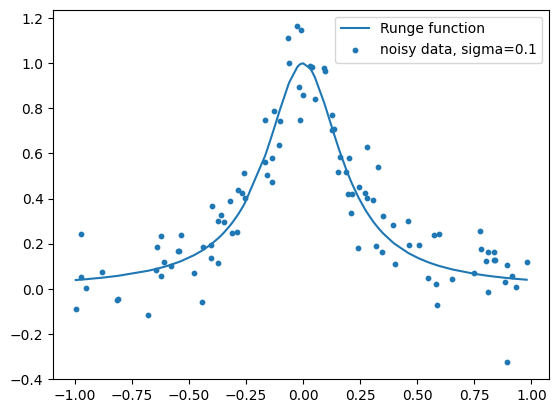

In [34]:
# The data of project 1, as a starting point for part b)
from neural_network_functions import *

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

X_scaled = (X - X.mean(axis=0)) / X.std(axis=0)  # Standardize the input features
y_scaled = (y - y.mean()) / y.std()  # Standardize the target variable

Yrunge = runge(X.flatten())
Yrunge_scaled = (Yrunge - Yrunge.mean()) / Yrunge.std()  # Standardize the Runge function values

In [27]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50, 1]
layers_one_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_one_hidden_layer = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_one_hidden_layer,
    activation_funcs = [sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


In [28]:
epochs = 1000
t0 = 1.0
t1 = 100.0
batch_size = 10

Xtrain, Xtest, ytrain, ytest = train_test_split(X_scaled, y_scaled, test_size=0.2, random_state=42)

input_size = 1
layer_output_sizes = [50,50, 1]
layers_two_hidden_layer = create_layers(input_size, layer_output_sizes)
layers_two_hidden_layer = train_sgd_adam(
    Xtrain = Xtrain,
    Ytrain = ytrain.reshape(-1, 1),
    layers = layers_two_hidden_layer,
    activation_funcs = [sigmoid, sigmoid, lambda z: z],  # Last layer is linear
    activation_ders = [sigmoid_der, sigmoid_der, lambda z: np.ones_like(z)],
    epochs = epochs,
    batch_size = batch_size,
    gamma = 0.01,
    use_decaying_step_length = True,
    t0 = t0,
    t1 = t1  
)


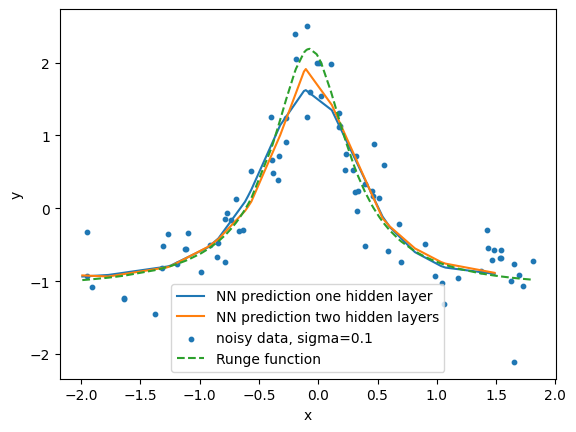

In [29]:
y_pred_one_hidden_layers = feed_forward(Xtest, layers_one_hidden_layer, [sigmoid, lambda z: z])
y_pred_two_hidden_layers = feed_forward(Xtest, layers_two_hidden_layer, [sigmoid, sigmoid, lambda z: z])
sort_idx = np.argsort(Xtest.flatten()) #<- Chatgpt la til fix

plt.plot(Xtest[sort_idx], y_pred_one_hidden_layers[sort_idx], label="NN prediction one hidden layer")
plt.plot(Xtest[sort_idx], y_pred_two_hidden_layers[sort_idx], label="NN prediction two hidden layers")

plt.scatter(Xtrain, ytrain, s=10, label=f"noisy data, sigma={sigma}")
plt.plot(X_scaled, Yrunge_scaled, label="Runge function", linestyle="--")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()

In [30]:
MSE_one_hidden = np.mean((y_pred_one_hidden_layers.flatten() - ytest)**2)
print(f"MSE for one hidden layer: {MSE_one_hidden}")

MSE_two_hidden = np.mean((y_pred_two_hidden_layers.flatten() - ytest)**2)
print(f"MSE for two hidden layers: {MSE_two_hidden}")

MSE for one hidden layer: 0.1595781296491623
MSE for two hidden layers: 0.138874813914299


In [35]:
cost_grad = jax.grad(cost, argnums=0)

layers = create_layers(1,[50, 1])

layer_grads = backpropagation(Xtrain, layers, [sigmoid, lambda z: z], target = ytrain.reshape(-1,1), activation_ders = [sigmoid_der, lambda z: np.ones_like(z)])

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, Xtrain, [sigmoid, lambda z: z], ytrain.reshape(-1, 1))
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

TypeError: Gradient only defined for scalar-output functions. Output was None.

In [ ]:
cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, x, [sigmoid, ReLU], target)
print(layer_grads_jax)

# the check: every dW and db agrees with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

NameError: name 'jax' is not defined

In [ ]:
functions = [ReLU, leaky_ReLU, sigmoid]
number_of_nodes = np.arange(2,10,2)  # Example range of nodes
number_of_hidden_layers = np.arange(1, 4)  # Example range of hidden layers

for function in functions:
    for n_layers in number


SyntaxError: expected ':' (805249612.py, line 6)